# S11: Periodic U-Net baseline

This notebook presents the outputs of `s11_results.py`. Those outputs score the U-Net trained by `urbanwind.dl.train` on every held-out development case, exactly as S07 was scored. The notebook only reads saved outputs; the stage card is `README.md`.

**Protocol in brief.**
- **Folds.** Each outer fold trains on the other four grouped folds.
- **Stopping.** Whole cities and layout families from those training folds, balanced between the idealized and realistic subsets, decide when to stop. The scored fold is never used for this.
- **Prediction.** A moving average of the weights predicts every case of the scored fold whole. It is averaged over the case's exact symmetric copies and returned to the case's native grid.
- **Scoring.** Scores come from the same metric code as Phase 1.
- **Runs.** Three training seeds of the tuned settings (`configs/unet_tuned.yaml`), each over all five folds.

In [1]:
import json
import pathlib

import numpy as np
import pandas as pd
from IPython.display import Image, display

OUT = pathlib.Path.cwd()
while not (OUT / "pyproject.toml").exists():
    OUT = OUT.parent
OUT = OUT / "pipeline" / "S11_unet_baseline" / "outputs"
FIG = OUT / "figures"
pd.set_option("display.precision", 3)
summary = pd.read_csv(OUT / "summary.csv")
per_case = pd.read_csv(OUT / "per_case_metrics.csv")
SEEDS = [f"s11_unet_tuned_seed{s}" for s in range(3)]

## 1. Against S07

- **Pooled R²** rewards getting each case's level right.
- **Median per-case R²** rewards only the pattern inside each case.
- **Mean absolute error** is the mean of the per-case values, in units of u\* and in m/s.

S07 is the Phase 1 pixel model, scored on the same grouped folds.

In [2]:
cols = ["variant", "subset", "n_cases", "pooled_r2", "median_within_case_r2", "mean_mae", "mean_mae_ms"]
grouped = summary[summary["split"] == "grouped"]
display(grouped[cols].sort_values(["subset", "pooled_r2"], ascending=[True, False]).reset_index(drop=True))

,variant,subset,n_cases,pooled_r2,median_within_case_r2,mean_mae,mean_mae_ms
0,s11_unet_tuned_seed1,all,482,0.712,0.560,0.484,0.100
1,s11_unet_tuned_seed2,all,482,0.711,0.595,0.472,0.098
2,s11_unet_tuned_seed0,all,482,0.709,0.566,0.486,0.100
3,s07_pixel_gbm,all,482,0.591,0.304,0.611,0.126
4,s07_level_oracle,all,482,0.311,-0.000,0.816,0.169
5,s11_unet_tuned_seed1,"all, without flagged",476,0.712,0.559,0.484,0.100
6,s11_unet_tuned_seed2,"all, without flagged",476,0.711,0.595,0.472,0.097
7,s11_unet_tuned_seed0,"all, without flagged",476,0.709,0.565,0.485,0.100
8,s07_pixel_gbm,"all, without flagged",476,0.591,0.303,0.611,0.126
9,s07_level_oracle,"all, without flagged",476,0.312,-0.000,0.815,0.169


## 2. Seed to seed

Each training seed is a full five-fold run. The spread shows how much of a difference between two models could be luck.

In [3]:
seeds = summary[summary["variant"].isin(SEEDS)]
display(seeds.groupby("subset")[["pooled_r2", "median_within_case_r2", "mean_mae"]].agg(["mean", "min", "max"]))

pooled_r2               median_within_case_r2         \
                          mean    min    max                  mean    min   
subset                                                                      
all                      0.711  0.709  0.712                 0.574  0.560   
all, without flagged     0.711  0.709  0.712                 0.573  0.559   
idealized                0.939  0.935  0.944                 0.657  0.621   
realistic                0.678  0.677  0.680                 0.530  0.523   

                            mean_mae                
                        max     mean    min    max  
subset                                              
all                   0.595    0.481  0.472  0.486  
all, without flagged  0.595    0.480  0.472  0.485  
idealized             0.683    0.305  0.293  0.311  
realistic             0.544    0.595  0.589  0.599

## 3. Against S07, with uncertainty

Each seed minus S07 on the same cases. Positive is better for R², and negative is better for the error.

- **Intervals.** The 95% intervals come from resampling whole cities and layout families (2,000 times), as in Phase 1, so cases from one city are not treated as independent.
- **Cases and folds won.** The last two columns give the share of cases where the U-Net is better and the number of the five folds it wins.

In [4]:
display(pd.read_csv(OUT / "vs_s07.csv"))

,run,subset,metric,difference,ci_low,ci_high,share_of_cases_better,folds_better
0,s11_unet_tuned_seed0,all,pooled_r2,0.118,0.082,0.165,0.969,5
1,s11_unet_tuned_seed0,all,median_case_r2,0.262,0.220,0.289,0.969,5
2,s11_unet_tuned_seed0,all,mean_mae,-0.126,-0.146,-0.104,0.967,5
3,s11_unet_tuned_seed0,idealized,pooled_r2,0.059,0.051,0.074,0.963,5
4,s11_unet_tuned_seed0,idealized,median_case_r2,0.249,0.135,0.275,0.963,5
5,s11_unet_tuned_seed0,idealized,mean_mae,-0.082,-0.098,-0.062,0.963,5
6,s11_unet_tuned_seed0,realistic,pooled_r2,0.127,0.086,0.185,0.973,5
7,s11_unet_tuned_seed0,realistic,median_case_r2,0.276,0.231,0.323,0.973,5
8,s11_unet_tuned_seed0,realistic,mean_mae,-0.154,-0.186,-0.123,0.969,5
9,s11_unet_tuned_seed1,all,pooled_r2,0.121,0.086,0.168,0.967,5


## 4. Case by case and on the map

- **Scatter.** Each dot is a held-out case of the first seed. Above the diagonal, the U-Net explains more of the pattern inside the case than S07 does.
- **Maps.** They show the same three realistic cases S07 showed: its worst, median and best.

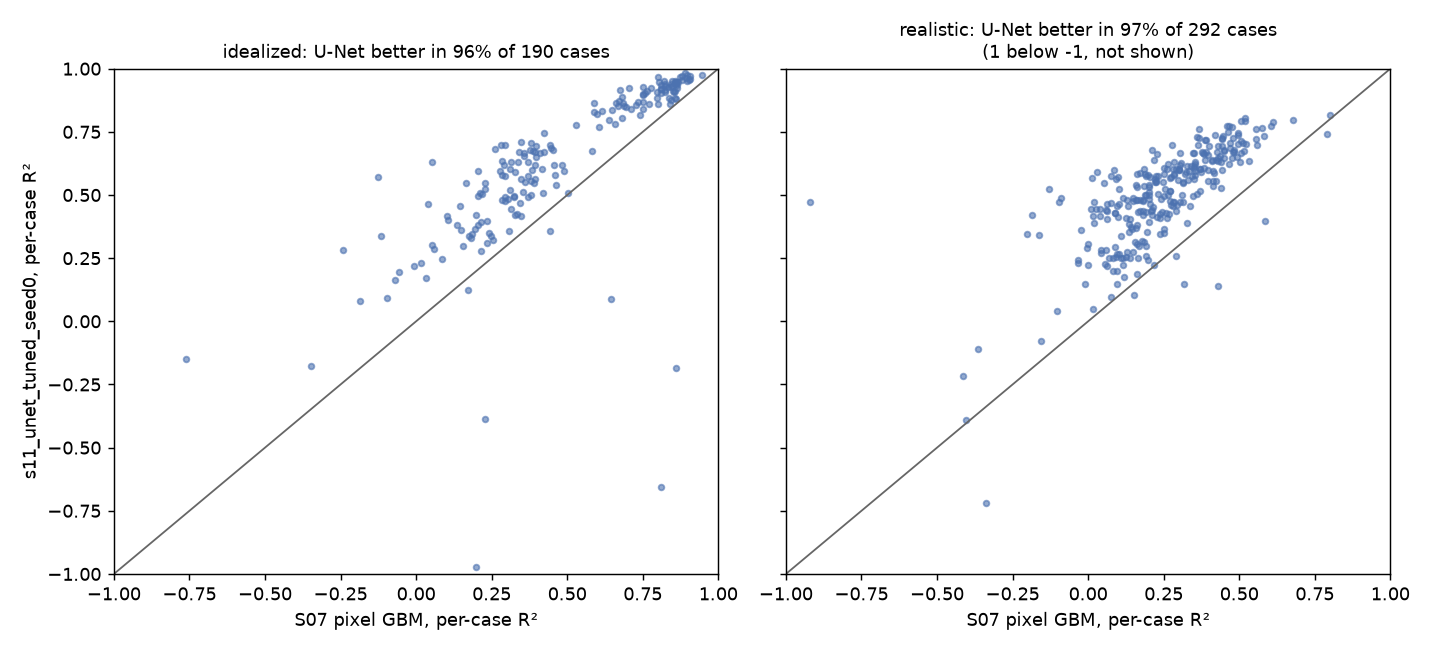

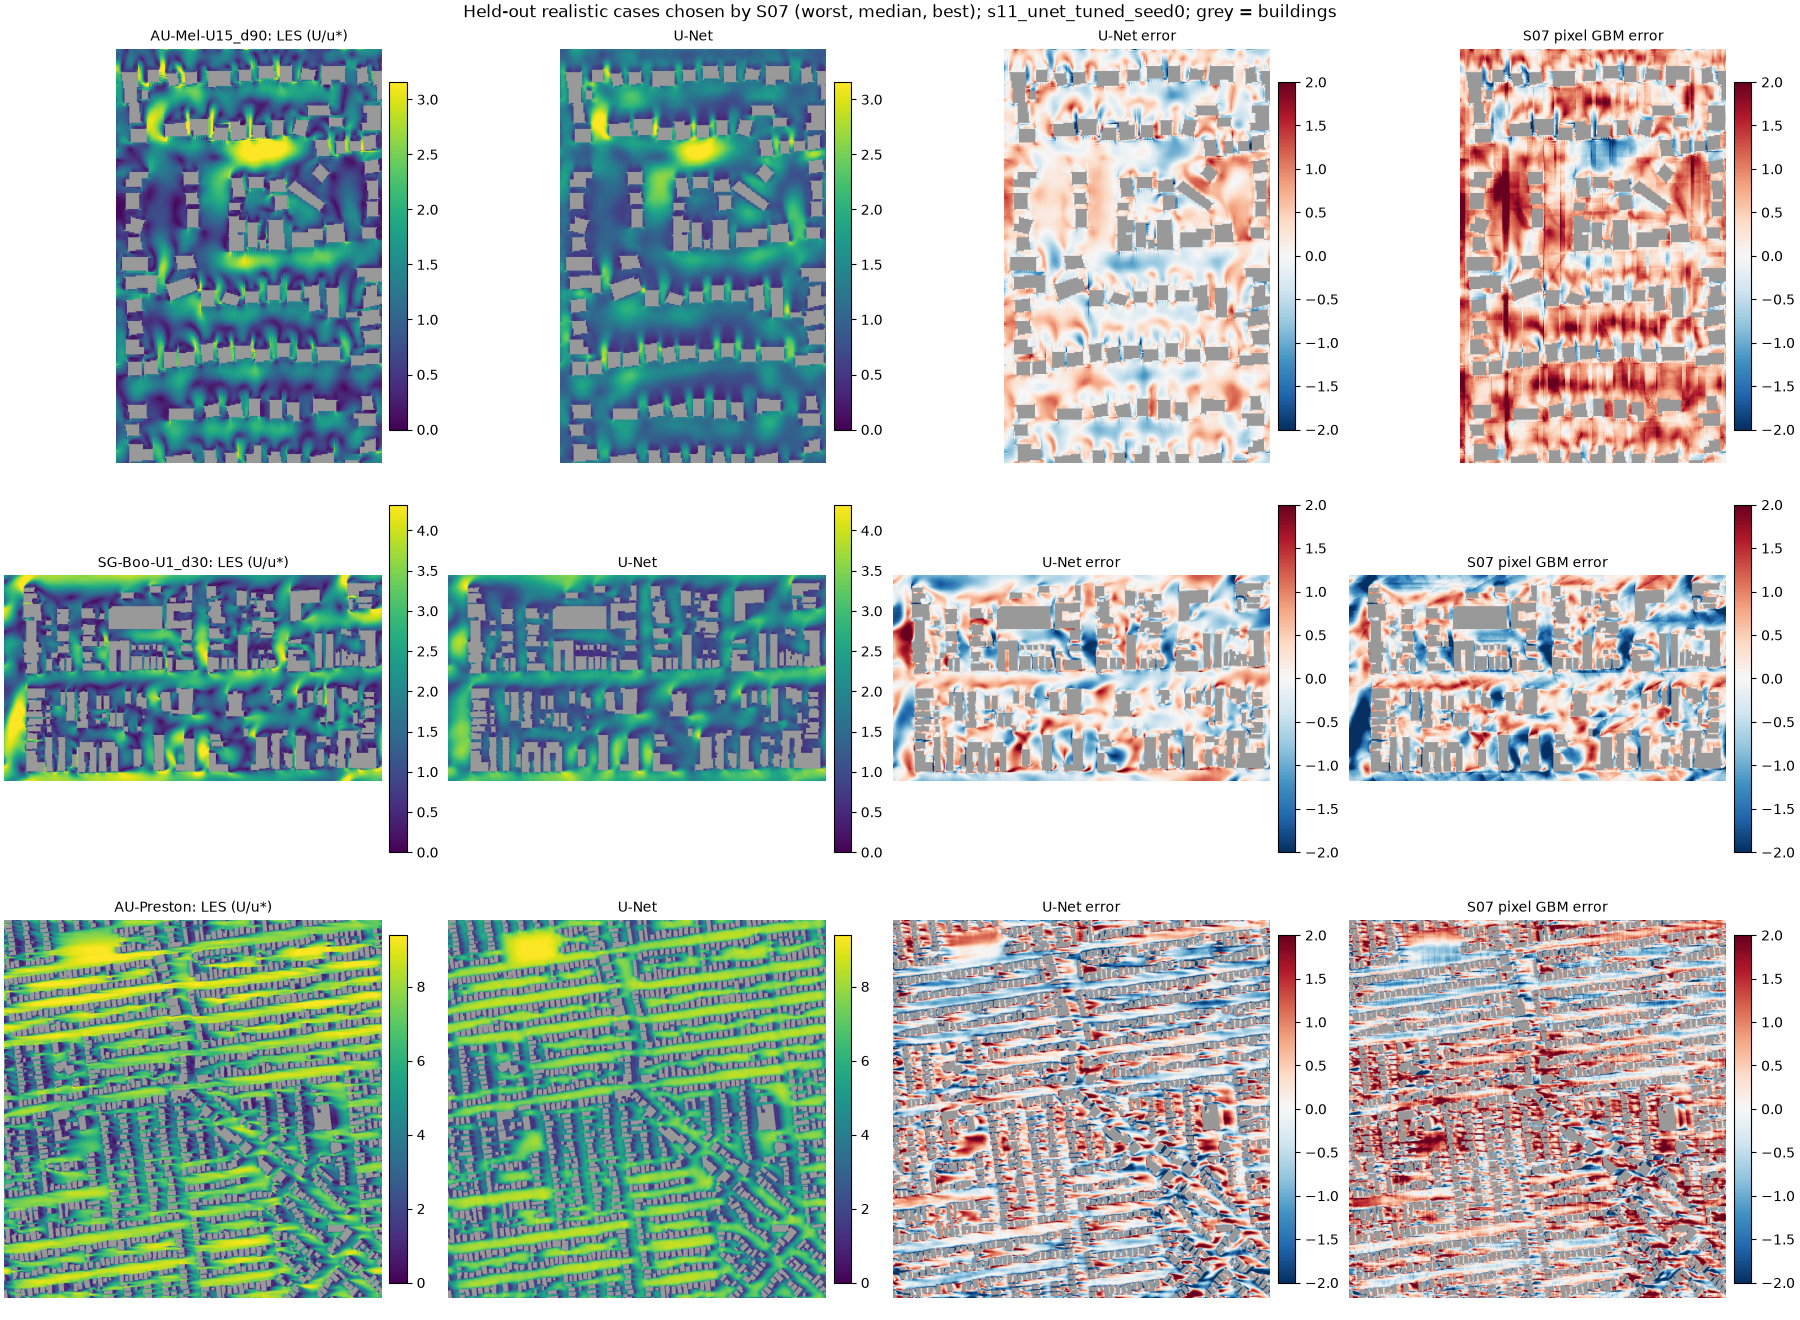

In [5]:
display(Image(FIG / "per_case_vs_s07.png"))
display(Image(FIG / "error_maps_realistic.png"))

## 5. Training

Every fold ran the full 100 epochs; the inner-validation error is the balanced RMSE the run selected on. Most folds keep their last epoch: the learning rate decays to its floor along a cosine, so the error flattens towards the end rather than turning up.

,run,fold,epochs_run,best_epoch,best_val,minutes,device,n_fit,n_val
0,s11_unet_tuned_seed0,0,100,99,0.599,65.9,cuda,324,61
1,s11_unet_tuned_seed0,1,100,99,0.609,66.1,cuda,318,67
2,s11_unet_tuned_seed0,2,100,99,0.578,67.2,cuda,319,66
3,s11_unet_tuned_seed0,3,100,92,0.563,65.1,cuda,325,61
4,s11_unet_tuned_seed0,4,100,99,0.545,63.5,cuda,324,63
5,s11_unet_tuned_seed1,0,100,99,0.608,63.4,cuda,324,61
6,s11_unet_tuned_seed1,1,100,99,0.628,65.7,cuda,318,67
7,s11_unet_tuned_seed1,2,100,99,0.586,66.6,cuda,319,66
8,s11_unet_tuned_seed1,3,100,99,0.557,68.2,cuda,325,61
9,s11_unet_tuned_seed1,4,100,99,0.531,66.0,cuda,324,63


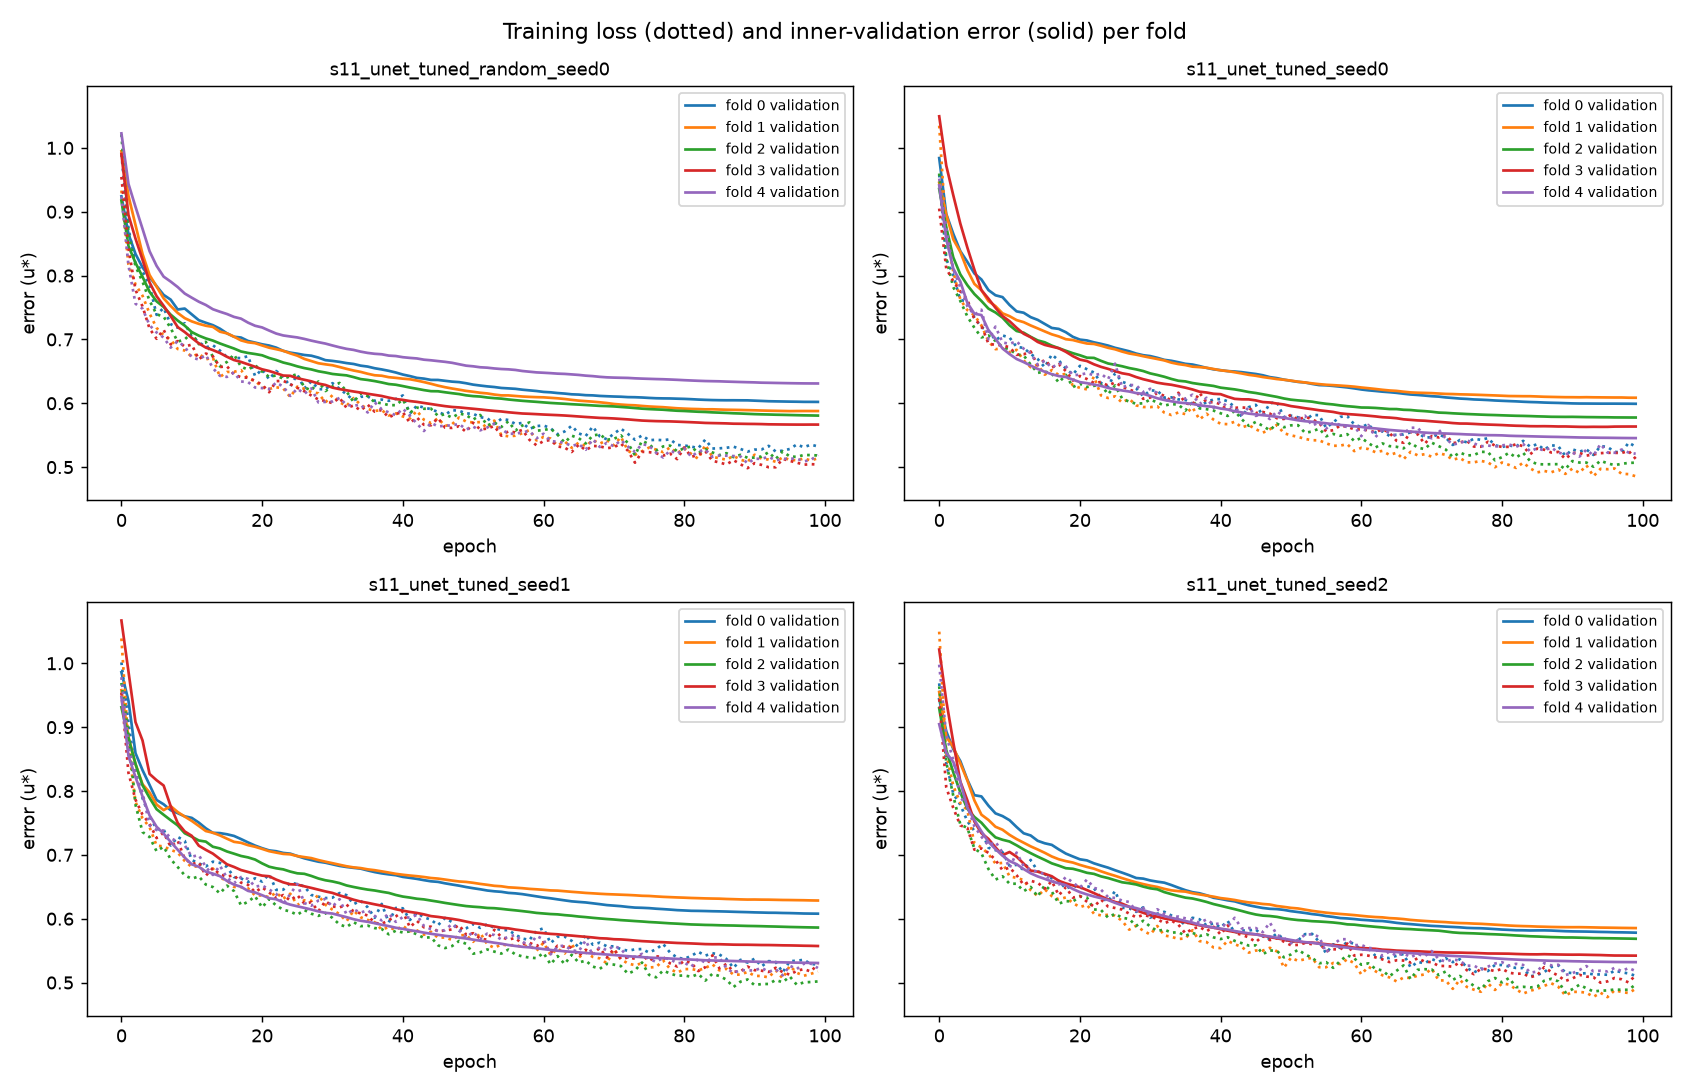

In [6]:
fold_info = pd.DataFrame([json.loads(p.read_text()) | {"run": p.parent.name}
                          for run in [*SEEDS, "s11_unet_tuned_random_seed0"]
                          for p in sorted((OUT / "runs" / run).glob("fold*.json"))])
display(fold_info[["run", "fold", "epochs_run", "best_epoch", "best_val", "minutes", "device", "n_fit", "n_val"]])
display(Image(FIG / "learning_curves.png"))

## 6. Fold 0: what the fixes and the tuning added

Fold 0's 97 scored cases only:
- **`s11_unet_v1_seed0`:** the first version of the recipe. It had unbalanced inner validation, selected on L1, had no weight averaging and copied 1 m predictions onto 0.5 m grids.
- **`s11_unet_seed0`:** the final code with the default settings.
- **`s11_unet_tuned_seed0` to `seed2`:** the final code with the tuned settings.

The inner-validation RMSE is measured on the same held-back groups for every run except the first version.

In [7]:
display(pd.read_csv(OUT / "fold0_versions.csv"))

,run,n_cases,pooled_r2,median_case_r2,median_case_r2_idealized,median_case_r2_realistic,mean_mae,inner_val_rmse
0,s11_unet_v1_seed0,97,0.777,0.552,0.467,0.560,0.478,NaN
1,s11_unet_seed0,97,0.787,0.572,0.545,0.581,0.466,0.608
2,s11_unet_tuned_seed0,97,0.791,0.590,0.565,0.601,0.457,0.599
3,s11_unet_tuned_seed1,97,0.789,0.567,0.525,0.583,0.465,0.608
4,s11_unet_tuned_seed2,97,0.802,0.633,0.594,0.633,0.442,0.578
5,s07_pixel_gbm,97,0.658,0.280,0.303,0.259,0.605,NaN


## 7. Leakage: a random split of the same cases

`s11_unet_tuned_random_seed0` uses the tuned settings, but deals the 482 cases into five folds at random, so a test case's city or layout family is usually also in training. A random split should flatter the model.

In [8]:
random_run = "s11_unet_tuned_random_seed0"
cols = ["variant", "split", "subset", "pooled_r2", "median_within_case_r2", "mean_mae"]
display(summary[summary["variant"].isin([*SEEDS, random_run])][cols].sort_values(["subset", "variant"]))

r2 = per_case.pivot_table(index="case", columns="run", values="r2")
better = (r2[random_run] > r2[SEEDS].mean(axis=1))
print(f"random split better than the mean of the grouped seeds in {better.sum()} of {len(better)} cases")

,variant,split,subset,pooled_r2,median_within_case_r2,mean_mae
8,s11_unet_tuned_random_seed0,random,all,0.683,0.593,0.471
12,s11_unet_tuned_seed0,grouped,all,0.709,0.566,0.486
16,s11_unet_tuned_seed1,grouped,all,0.712,0.560,0.484
20,s11_unet_tuned_seed2,grouped,all,0.711,0.595,0.472
11,s11_unet_tuned_random_seed0,random,"all, without flagged",0.683,0.592,0.471
15,s11_unet_tuned_seed0,grouped,"all, without flagged",0.709,0.565,0.485
19,s11_unet_tuned_seed1,grouped,"all, without flagged",0.712,0.559,0.484
23,s11_unet_tuned_seed2,grouped,"all, without flagged",0.711,0.595,0.472
9,s11_unet_tuned_random_seed0,random,idealized,0.938,0.671,0.309
13,s11_unet_tuned_seed0,grouped,idealized,0.935,0.667,0.311


random split better than the mean of the grouped seeds in 312 of 482 cases


The median per-case R² and most single cases are better under the random split, as expected. The pooled R² is lower, and one case explains it: **AU-Preston**, the largest Melbourne case (750,911 open cells).
- **What makes it unusual.** Its mean speed is 5.49 u\*, twice that of any other Melbourne case.
- **The grouped models.** They never see Melbourne when they predict it, and they get its level right.
- **The random-split model.** It was trained on most of the other Melbourne cases, which are all much slower, and predicts about 2.1 u\*.

The table below rebuilds the pooled R² from the saved per-case values, with and without that case. The first rows check that the rebuilt values match `summary.csv`.

In [9]:
def pooled(rows: pd.DataFrame) -> float:
    n = rows["n"]
    sse = (rows["rmse"] ** 2 * n).sum()
    s, ss = (rows["mean_true"] * n).sum(), ((rows["var_true"] + rows["mean_true"] ** 2) * n).sum()
    return 1 - sse / (ss - s * s / n.sum())


rows = []
for run in [*SEEDS, random_run]:
    sub = per_case[per_case["run"] == run]
    preston = sub[sub["case"] == "AU-Preston"].iloc[0]
    rows.append({"run": run, "pooled_r2_rebuilt": pooled(sub),
                 "pooled_r2_in_summary": summary.query("variant == @run and subset == 'all'")["pooled_r2"].iloc[0],
                 "pooled_r2_without_AU_Preston": pooled(sub[sub["case"] != "AU-Preston"]),
                 "AU_Preston_r2": preston["r2"], "AU_Preston_true_mean": preston["mean_true"],
                 "AU_Preston_size_of_mean_error": float(np.sqrt(preston["level_err"]))})
display(pd.DataFrame(rows))

,run,pooled_r2_rebuilt,pooled_r2_in_summary,pooled_r2_without_AU_Preston,AU_Preston_r2,AU_Preston_true_mean,AU_Preston_size_of_mean_error
0,s11_unet_tuned_seed0,0.709,0.709,0.692,0.816,5.488,0.055
1,s11_unet_tuned_seed1,0.712,0.712,0.695,0.818,5.488,0.139
2,s11_unet_tuned_seed2,0.711,0.711,0.694,0.807,5.488,0.253
3,s11_unet_tuned_random_seed0,0.683,0.683,0.723,-1.250,5.488,3.397
